In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
data_collected = pd.read_csv("../data/assignment3Experiment.csv")

In [9]:
data_collected.info()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   participant_id      48 non-null     str  
 1   group               48 non-null     int64
 2   is_pilot            48 non-null     str  
 3   presentation_order  48 non-null     str  
 4   question_order      48 non-null     int64
 5   condition           48 non-null     str  
 6   task                48 non-null     int64
 7   variant             48 non-null     str  
 8   range               48 non-null     str  
 9   expected_answer     48 non-null     str  
 10  answer_given        48 non-null     str  
 11  correct             48 non-null     int64
 12  time_seconds        48 non-null     int64
 13  timed_out           48 non-null     str  
dtypes: int64(5), str(9)
memory usage: 7.5 KB


In [10]:
data_collected["condition"] = data_collected["condition"].str.strip()
data_collected["condition"].value_counts()

condition
Static         24
Interactive    24
Name: count, dtype: int64

In [12]:
remove_pilot = data_collected[data_collected["is_pilot"] == "no"]
print("Number of participants:", remove_pilot["participant_id"].nunique())
print(len(remove_pilot))

Number of participants: 10
40


## Chart 1: Accuracy

### Task accuracy: Whether participants correctly complete each task.

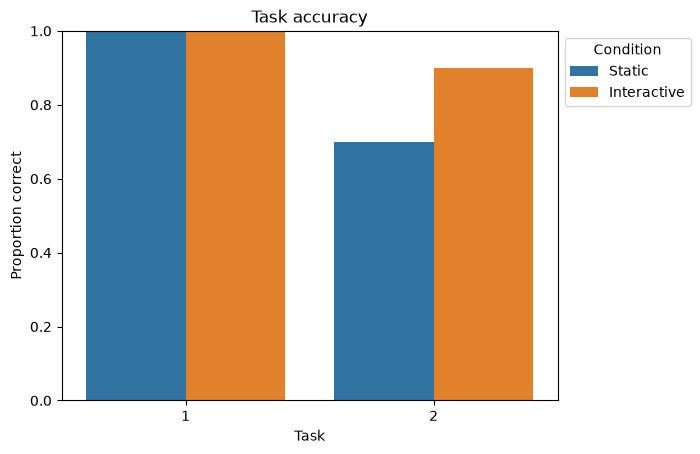

In [26]:
ax = sns.barplot(remove_pilot, x = "task", y = "correct", hue = "condition", errorbar = None)
ax.set_xlabel("Task")
ax.set_ylabel("Proportion correct")
ax.set_title("Task accuracy")
ax.set_ylim(0,1)
sns.move_legend(ax, "upper left", bbox_to_anchor = (1,1), title = "Condition")
plt.show()

## Chart 2: Completion time

### Task completion time: The time, in seconds, required to complete each task.

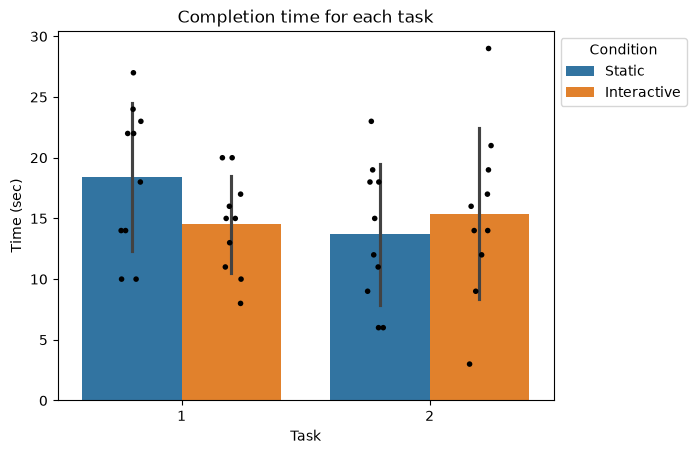

In [38]:
ax = sns.barplot(remove_pilot, x = "task", y = "time_seconds", hue = "condition", errorbar = "sd")
sns.stripplot(remove_pilot, x = "task", y = "time_seconds", palette = ["black", "black"], hue = "condition", dodge = True, size = 4, legend = False, ax = ax)
ax.set_xlabel("Task")
ax.set_ylabel("Time (sec)")
ax.set_title("Completion time for each task")
sns.move_legend(ax, "upper left", bbox_to_anchor = (1,1), title = "Condition")
plt.show()

## Participants

In [48]:
participants = remove_pilot.groupby(["participant_id", "condition"])["time_seconds"].mean().unstack()
participants["time_difference"] = participants["Interactive"] - participants["Static"]
participants

condition,Interactive,Static,time_difference
participant_id,,,
P03,19.5,18.0,1.5
P04,11.5,17.0,-5.5
P05,23.0,12.0,11.0
P06,12.0,8.0,4.0
P07,14.5,16.0,-1.5
P08,13.5,12.5,1.0
P09,15.5,21.0,-5.5
P10,11.0,21.0,-10.0
P11,15.0,12.5,2.5


In [42]:
remove_pilot[remove_pilot["correct"] == 0]

,participant_id,group,is_pilot,presentation_order,question_order,condition,task,variant,range,expected_answer,answer_given,correct,time_seconds,timed_out
9,P03,2,no,Static first,3,Static,2,B,30-40,Car,Train,0,9,no
15,P04,3,no,Interactive first,2,Static,2,B,30-40,Car,Train,0,12,no
25,P07,2,no,Static first,3,Static,2,B,30-40,Car,Train,0,18,no
39,P10,1,no,Static first,4,Interactive,2,B,30-40,Car,Train,0,14,no


In [44]:
remove_pilot.groupby("presentation_order")["participant_id"].nunique()

presentation_order
Interactive first    6
Static first         4
Name: participant_id, dtype: int64